In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Chargement des données 
df =pd.read_csv("Auto Sales data.csv")

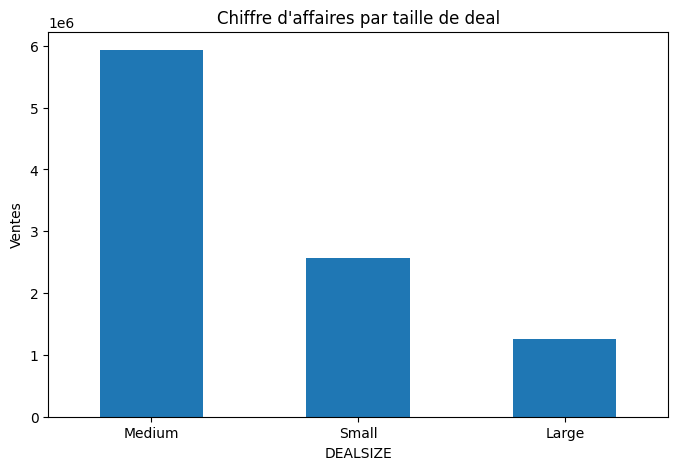

In [4]:
#Chiffre d’affaires par taille de deal
deal_sales = df.groupby("DEALSIZE")["SALES"].sum().sort_values(ascending=False)

deal_sales.plot(kind="bar", figsize=(8,5))
plt.title("Chiffre d'affaires par taille de deal")
plt.xticks(rotation=0)
plt.ylabel("Ventes")
plt.show()

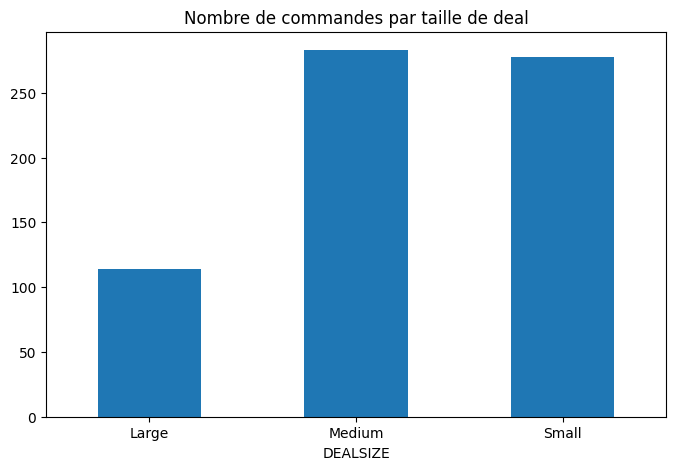

In [5]:
#Nombre de commandes par deal size
deal_orders = df.groupby("DEALSIZE")["ORDERNUMBER"].nunique()

deal_orders.plot(kind="bar", figsize=(8,5))
plt.title("Nombre de commandes par taille de deal")
plt.xticks(rotation=0)
plt.show()

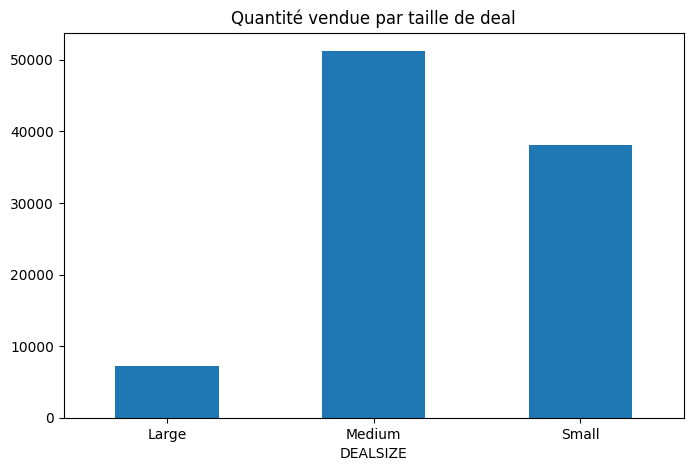

In [6]:
#Quantité vendue par deal size
deal_qty = df.groupby("DEALSIZE")["QUANTITYORDERED"].sum()

deal_qty.plot(kind="bar", figsize=(8,5))
plt.title("Quantité vendue par taille de deal")
plt.xticks(rotation=0)
plt.show()

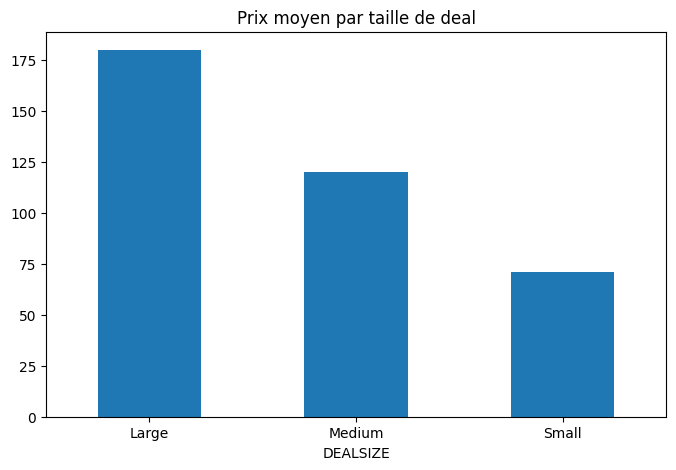

In [7]:
#Prix moyen par deal size
avg_price_deal = df.groupby("DEALSIZE")["PRICEEACH"].mean()

avg_price_deal.plot(kind="bar", figsize=(8,5))
plt.title("Prix moyen par taille de deal")
plt.xticks(rotation=0)
plt.show()

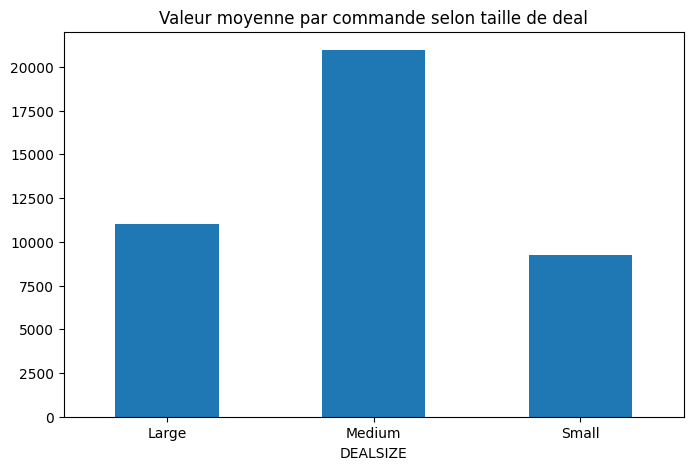

In [12]:
#CA moyen par commande (par deal size)
avg_sales_per_order = df.groupby("DEALSIZE").agg({
    "SALES": "sum",
    "ORDERNUMBER": "nunique"
})

avg_sales_per_order["AVG_ORDER_VALUE"] = avg_sales_per_order["SALES"] / avg_sales_per_order["ORDERNUMBER"]

avg_sales_per_order["AVG_ORDER_VALUE"].plot(kind="bar", figsize=(8,5))
plt.title("Valeur moyenne par commande selon taille de deal")
plt.xticks(rotation=0)
plt.show()

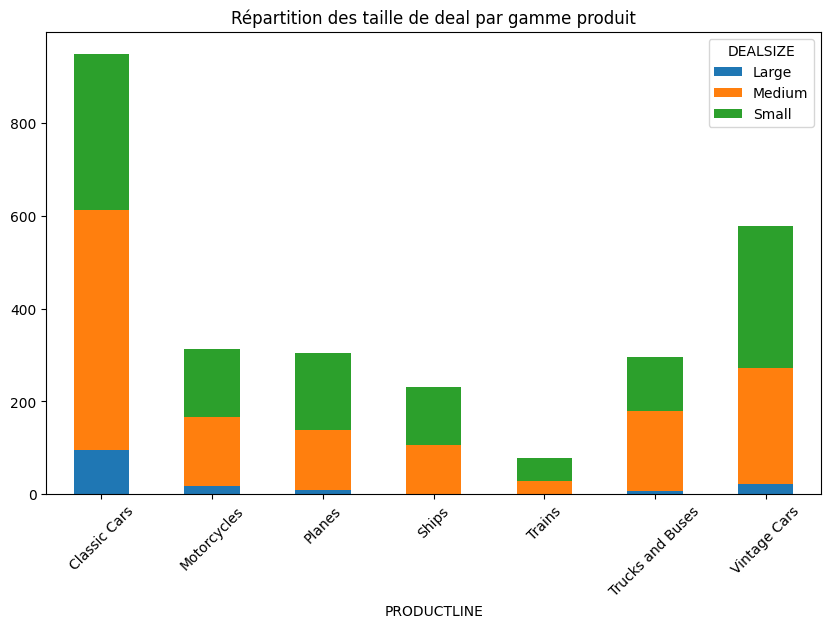

In [11]:
#Analyse croisée DEALSIZE vs PRODUCTLINE
deal_product = pd.crosstab(df["PRODUCTLINE"], df["DEALSIZE"])

deal_product.plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Répartition des taille de deal par gamme produit")
plt.xticks(rotation=45)
plt.show()

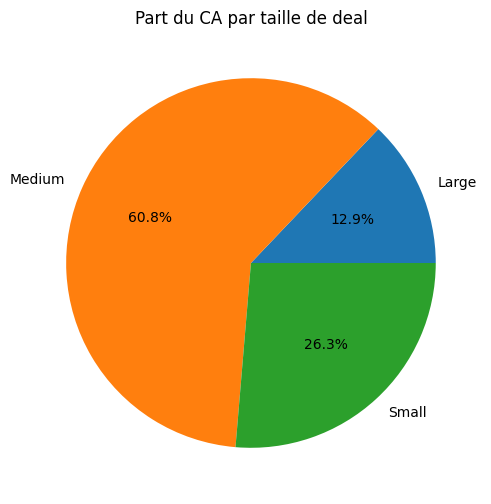

In [10]:
#Contribution des deals au chiffre d'affaires total
deal_share = df.groupby("DEALSIZE")["SALES"].sum()
deal_share = deal_share / deal_share.sum() * 100

deal_share.plot(kind="pie", autopct="%1.1f%%", figsize=(6,6))
plt.title("Part du CA par taille de deal")
plt.ylabel("")
plt.show()